# 09 - Phân tích đơn biến và hai biến trên dữ liệu chim cánh cụt

Mục tiêu: bài mẫu 1.3.2 (bài toán 1 nhiệm vụ 1 và bài toán 2 nhiệm vụ 1): histogram, bar chart, pie chart, scatter plot, crosstab, pivot_table, pairplot.

## 1. Load data và kiểm tra nhanh

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

penguins = pd.read_csv(can_file('penguins_size.csv'))
kiem_tra_chat_luong(penguins, 'Penguins')
print('Giá trị lạ ở cột sex:', penguins['sex'].value_counts(dropna=False).to_dict())
penguins['sex'] = penguins['sex'].replace('.', np.nan)  
display(penguins.head())

=== Penguins ===
Shape: (344, 4)
Số dòng trùng lặp: 5
Giá trị thiếu theo cột:
culmen_length_mm     2
body_mass_g          2
sex                 10
dtype: int64
Giá trị lạ ở cột sex: {'MALE': 168, 'FEMALE': 165, nan: 10, '.': 1}


,species,culmen_length_mm,body_mass_g,sex
0,Adelie Penguin (Pygoscelis adeliae),39.1,3750.0,MALE
1,Adelie Penguin (Pygoscelis adeliae),39.5,3800.0,FEMALE
2,Adelie Penguin (Pygoscelis adeliae),40.3,3250.0,FEMALE
3,Adelie Penguin (Pygoscelis adeliae),NaN,NaN,NaN
4,Adelie Penguin (Pygoscelis adeliae),36.7,3450.0,FEMALE


## 2. Đơn biến: histogram cho `culmen_length_mm`

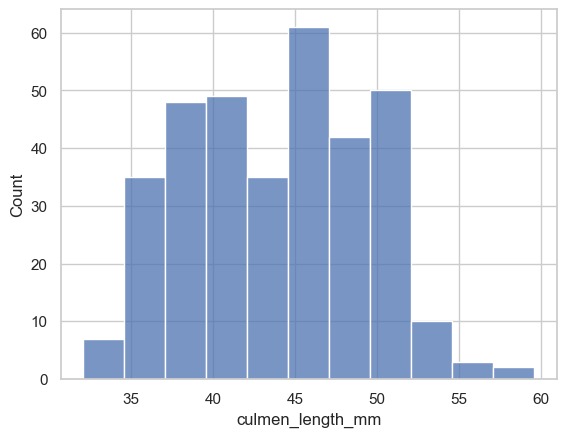

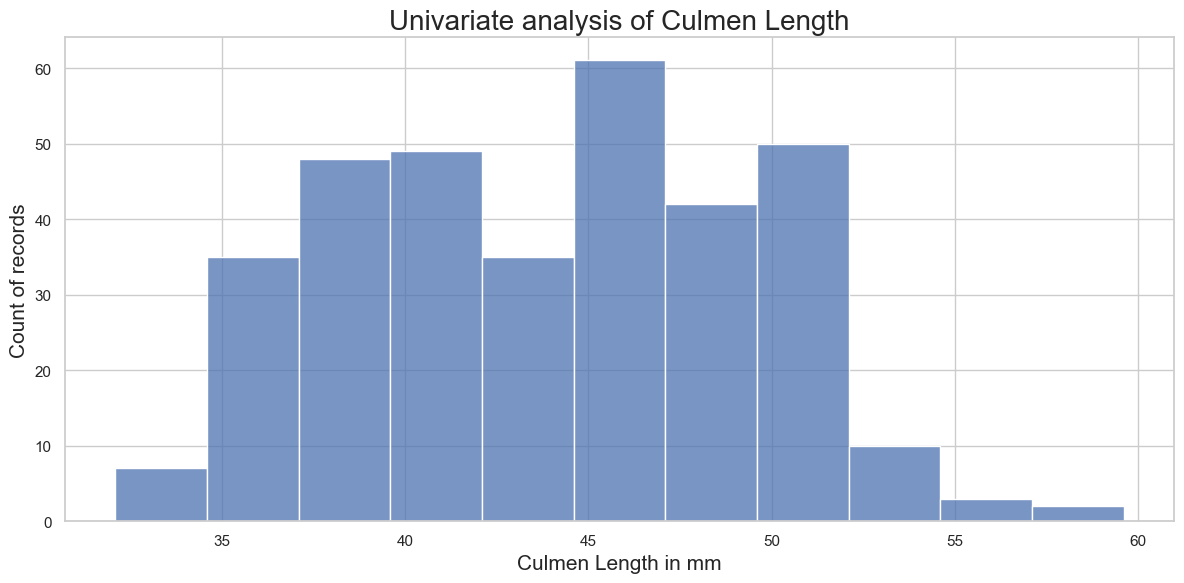

count    342.00
mean      43.92
std        5.46
min       32.10
25%       39.22
50%       44.45
75%       48.50
max       59.60
Name: culmen_length_mm, dtype: float64


In [2]:
sns.histplot(data=penguins, x='culmen_length_mm')
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.histplot(data=penguins, x='culmen_length_mm')
ax.set_xlabel('Culmen Length in mm', fontsize=15)
ax.set_ylabel('Count of records', fontsize=15)
ax.set_title('Univariate analysis of Culmen Length', fontsize=20)
luu_hinh('09_penguins_hist_culmen_length')
print(penguins['culmen_length_mm'].describe().round(2))

## 3. Đơn biến: bar chart và pie chart cho `species`

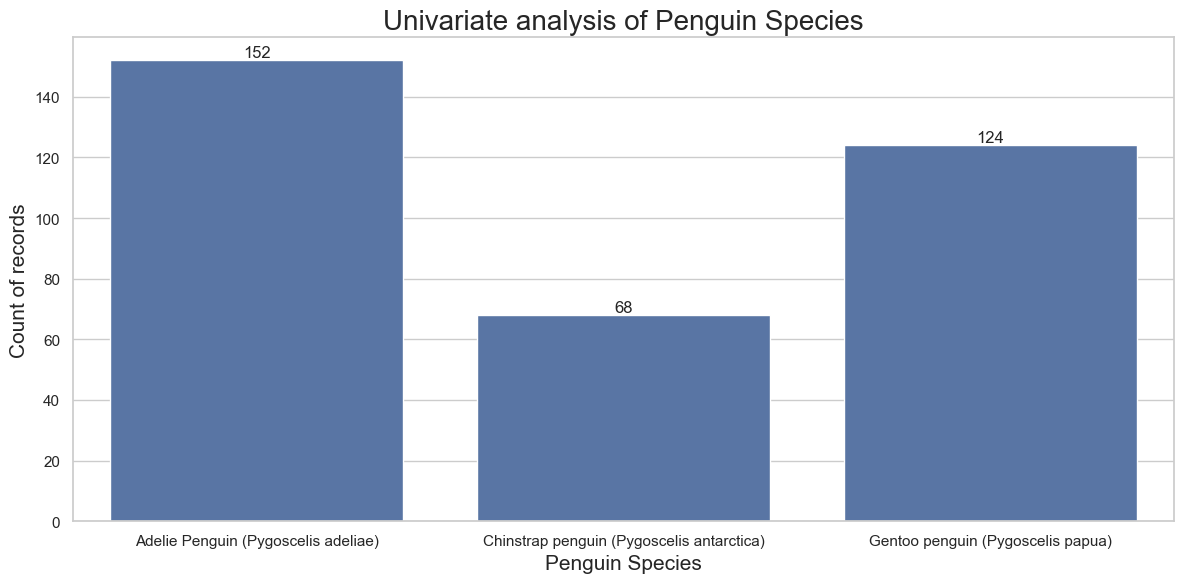

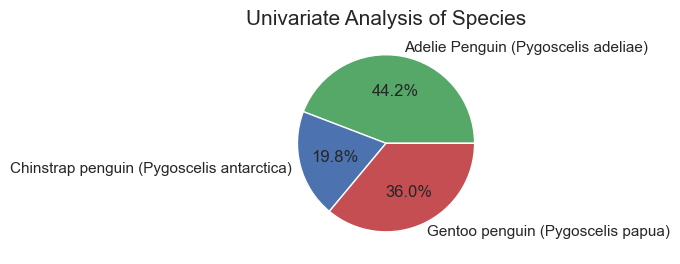

In [3]:
plt.figure(figsize=(12, 6))
ax = sns.countplot(data=penguins, x='species')
ax.bar_label(ax.containers[0])
ax.set_xlabel('Penguin Species', fontsize=15)
ax.set_ylabel('Count of records', fontsize=15)
ax.set_title('Univariate analysis of Penguin Species', fontsize=20)  
luu_hinh('09_penguins_bar_species')

plt.figure(figsize=(6, 6))
penguins['species'].value_counts().sort_index().plot.pie(autopct='%1.1f%%', colors=['g', 'b', 'r'])
plt.title('Univariate Analysis of Species', fontsize=15); plt.ylabel('')
luu_hinh('09_penguins_pie_species')

## 4. Hai biến: scatter plot

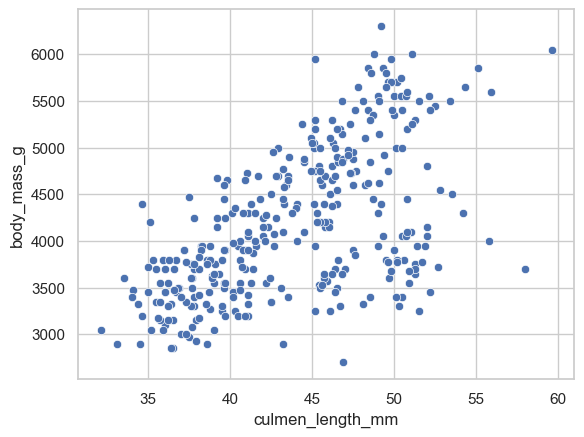

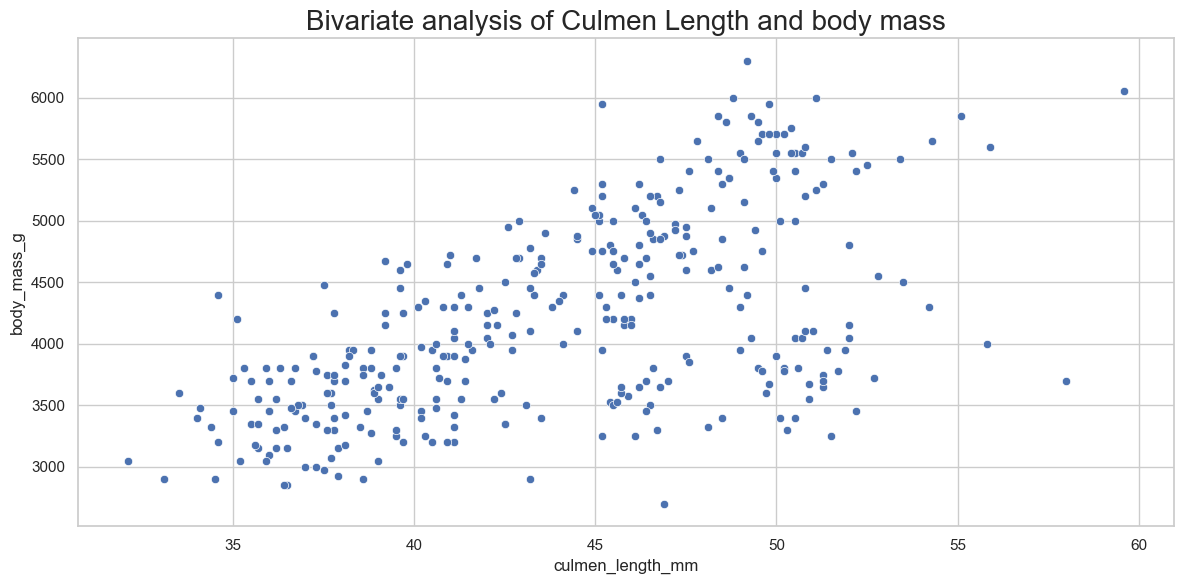

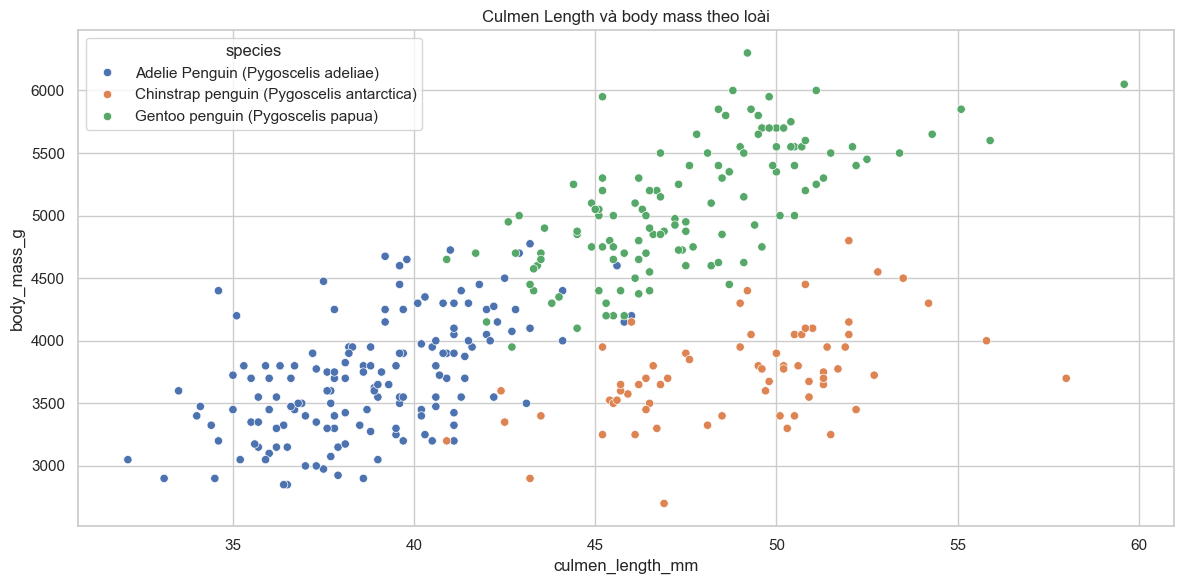

Tương quan chung: 0.595
  Adelie Penguin (Pygoscelis adeliae): r = 0.549
  Chinstrap penguin (Pygoscelis antarctica): r = 0.514
  Gentoo penguin (Pygoscelis papua): r = 0.669


In [4]:
sns.scatterplot(data=penguins, x='culmen_length_mm', y='body_mass_g')
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.scatterplot(data=penguins, x='culmen_length_mm', y='body_mass_g')
ax.set_title('Bivariate analysis of Culmen Length and body mass', fontsize=20)
luu_hinh('09_penguins_scatter')

plt.figure(figsize=(12, 6))
sns.scatterplot(data=penguins, x='culmen_length_mm', y='body_mass_g', hue='species')
plt.title('Culmen Length và body mass theo loài')
luu_hinh('09_penguins_scatter_by_species')
print('Tương quan chung:', round(penguins['culmen_length_mm'].corr(penguins['body_mass_g']), 3))
for sp, g in penguins.groupby('species'):
    print(f'  {sp}: r = {g["culmen_length_mm"].corr(g["body_mass_g"]):.3f}')

## 5. Hai biến: crosstab, pivot_table, pairplot

sex,FEMALE,MALE
species,,
Adelie Penguin (Pygoscelis adeliae),73,73
Chinstrap penguin (Pygoscelis antarctica),34,34
Gentoo penguin (Pygoscelis papua),58,61


,culmen_length_mm
species,
Adelie Penguin (Pygoscelis adeliae),38.791391
Chinstrap penguin (Pygoscelis antarctica),48.833824
Gentoo penguin (Pygoscelis papua),47.504878


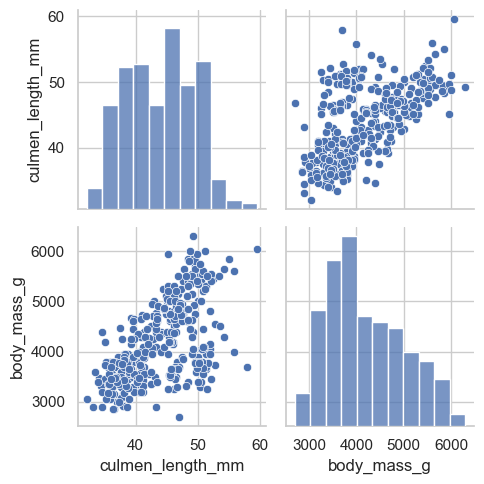

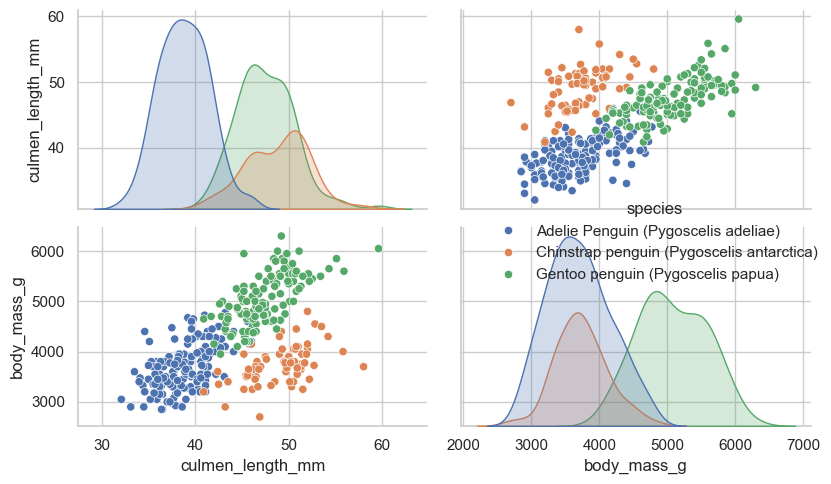

Đã cập nhật: results_summary.csv


In [5]:
display(pd.crosstab(index=penguins['species'], columns=penguins['sex']))
display(pd.pivot_table(penguins, values='culmen_length_mm', index='species', aggfunc='mean'))

sns.pairplot(data=penguins[['species', 'culmen_length_mm', 'body_mass_g']])
luu_hinh('09_penguins_pairplot')
sns.pairplot(data=penguins[['species', 'culmen_length_mm', 'body_mass_g']], hue='species')
luu_hinh('09_penguins_pairplot_by_species')
cap_nhat_summary('09_penguins_uni_bivariate', 'penguins_size.csv', penguins)

## 6. Nhận xét

Histogram của `culmen_length_mm` có nhiều đỉnh vì dữ liệu gộp ba loài với kích thước khác nhau; khi tách theo loài (pairplot có `hue`) từng nhóm gần dạng chuông hơn. Tương quan chung giữa culmen length và body mass có thể khác so với tương quan trong từng loài (hiện tượng Simpson), nên cần so sánh số liệu in ở bước 4 trước khi kết luận. Crosstab species x sex cho thấy số lượng đực/cái gần cân bằng trong mỗi loài.